In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Đọc dữ liệu sạch
df = pd.read_csv("data/phongtro_clean.csv")
print(f"Tổng số mẫu: {df.shape[0]} dòng | Số cột: {df.shape[1]} cột")

Tổng số mẫu: 1150 dòng | Số cột: 24 cột


C:\Users\bobby\AppData\Local\Temp\ipykernel_25956\2210084014.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top10, x="price", y="district", order=order_dist, ax=axes[2], palette="viridis")


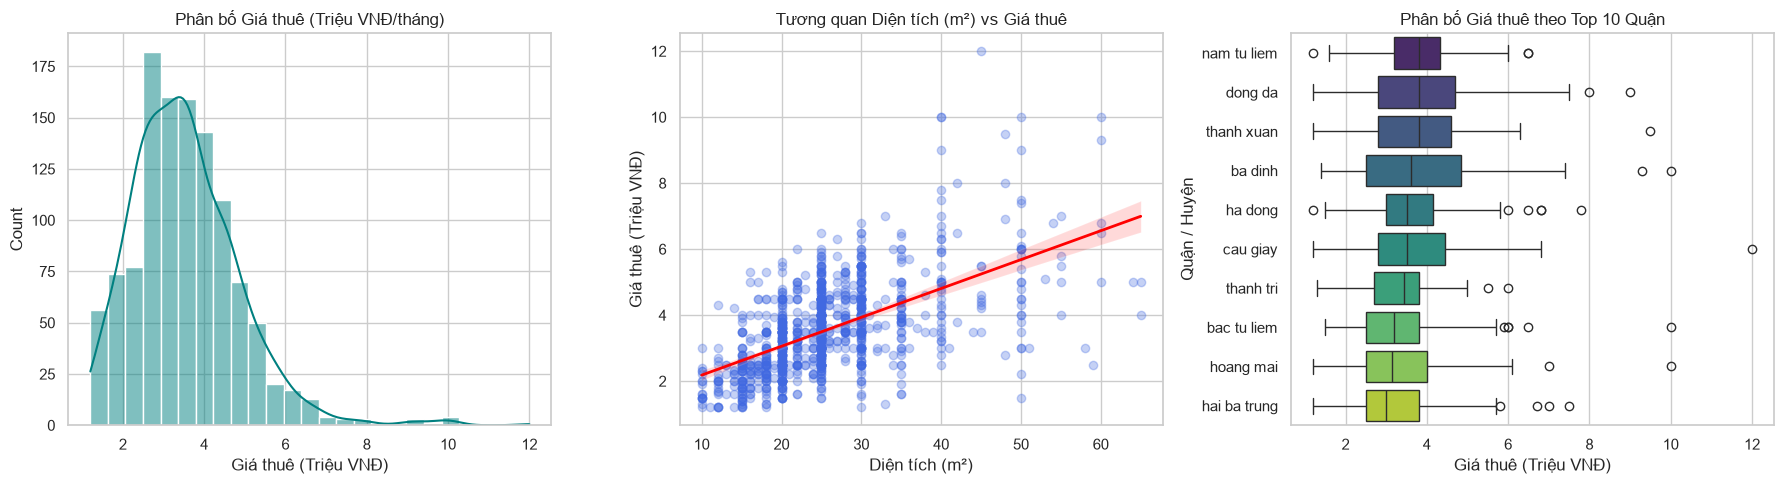

In [2]:
# Cấu hình hiển thị biểu đồ
plt.rcParams["figure.figsize"] = (10, 5)
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Phân bố giá thuê phòng
sns.histplot(df["price"], bins=25, kde=True, ax=axes[0], color="teal")
axes[0].set_title("Phân bố Giá thuê (Triệu VNĐ/tháng)")
axes[0].set_xlabel("Giá thuê (Triệu VNĐ)")

# 2. Tương quan giữa Diện tích và Giá thuê
sns.regplot(
    data=df, x="area", y="price", ax=axes[1],
    scatter_kws={"alpha": 0.3, "color": "royalblue"},
    line_kws={"color": "red", "linewidth": 2}
)
axes[1].set_title("Tương quan Diện tích (m²) vs Giá thuê")
axes[1].set_xlabel("Diện tích (m²)")
axes[1].set_ylabel("Giá thuê (Triệu VNĐ)")

# 3. Giá thuê trung bình tại Top 10 Quận nhiều tin nhất
top10_dist = df["district"].value_counts().head(10).index
df_top10 = df[df["district"].isin(top10_dist)]
order_dist = df_top10.groupby("district")["price"].median().sort_values(ascending=False).index

sns.boxplot(data=df_top10, x="price", y="district", order=order_dist, ax=axes[2], palette="viridis")
axes[2].set_title("Phân bố Giá thuê theo Top 10 Quận")
axes[2].set_xlabel("Giá thuê (Triệu VNĐ)")
axes[2].set_ylabel("Quận / Huyện")

plt.tight_layout()
plt.show()

In [3]:
# 1. Chỉ giữ các quận có từ 15 mẫu trở lên để đảm bảo đủ dữ liệu cho cả Train và Test, các quận khác gộp lại với nhau
dist_counts = df["district"].value_counts()
valid_districts = dist_counts[dist_counts >= 15].index

df_model = df.copy()
df_model["district"] = df_model["district"].where(df_model["district"].isin(valid_districts), other="khac")

print(f"Có {len(valid_districts)} quận với hơn 15 mẫu và còn lại {len(dist_counts) - len(valid_districts)} quận là nhóm lại")

# 2. Danh sách các cột đặc trưng (Features)
binary_cols = [
    "has_ac", "has_loft", "has_balcony", "private_wc", "free_hours",
    "no_shared_owner", "has_elevator", "has_washer", "has_fridge",
    "furnished", "has_security", "has_parking"
]
feature_cols = ["area", "district", "ptype"] + binary_cols

df_model = df_model[feature_cols + ["price"]].dropna()
stratify_col = df_model["district"]  # Lưu lại để chia đều tỷ lệ Quận giữa Train và Test

# 3. One-Hot Encoding cho biến phân loại (district và ptype)
# Bắt buộc dùng drop_first=True để tránh bẫy đa cộng tuyến (Dummy Variable Trap)
df_encoded = pd.get_dummies(
    df_model, columns=["district", "ptype"], drop_first=True, dtype=int
)

X = df_encoded.drop(columns=["price"])
y = df_encoded["price"]

# 4. Chia tập Train (80%) và Test (20%) có phân tầng theo Quận
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=stratify_col
)

print(f"Kích thước tập Train: {X_train.shape}")
print(f"Kích thước tập Test : {X_test.shape}")

Có 13 quận với hơn 15 mẫu và còn lại 9 quận là nhóm lại
Kích thước tập Train: (920, 29)
Kích thước tập Test : (230, 29)


In [5]:
model = LinearRegression()
model.fit(X_train, y_train)

y_train_predict = model.predict(X_train)
y_test_predict = model.predict(X_test)

def check_number(y_true, y_predict, name):
    mae = mean_absolute_error(y_true, y_predict)
    rmse = np.sqrt(mean_squared_error(y_true, y_predict))
    r2 = r2_score(y_true, y_predict)

    print(f"Tập {name}:")
    print(f"MAE     : {mae:.3f}")
    print(f"RMSE    : {rmse:.3f}")
    print(f"R^2     : {r2:.3f}")

check_number(y_train, y_train_predict, "Train")
check_number(y_test, y_test_predict, "Test")

Tập Train:
MAE     : 0.698
RMSE    : 0.956
R^2     : 0.480
Tập Test:
MAE     : 0.724
RMSE    : 0.965
R^2     : 0.476


In [6]:
weights_df = pd.DataFrame({
    "Feature": X.columns,
    "Weight_Million_VND": model.coef_
})

is_district = weights_df["Feature"].str.startswith("district_")
is_ptype    = weights_df["Feature"].str.startswith("ptype_")

sort_desc = lambda d: d.sort_values("Weight_Million_VND", ascending=False)

district_w = sort_desc(weights_df[is_district])
ptype_w    = sort_desc(weights_df[is_ptype])
other_w    = sort_desc(weights_df[~(is_district | is_ptype)])

print(f"Intercept: {model.intercept_:.3f} triệu VNĐ\n")
for title, g in [("DISTRICT", district_w), ("PTYPE", ptype_w), ("AREA & AMENITIES", other_w)]:
    print(f"--- {title} ---")
    display(g.round(3))

Intercept: 1.847 triệu VNĐ

--- DISTRICT ---


,Feature,Weight_Million_VND
15,district_dong da,0.052
23,district_tay ho,0.028
25,district_thanh xuan,-0.077
17,district_hai ba trung,-0.158
14,district_cau giay,-0.307
22,district_nam tu liem,-0.367
16,district_ha dong,-0.399
24,district_thanh tri,-0.466
19,district_hoang mai,-0.531
13,district_bac tu liem,-0.659


--- PTYPE ---


,Feature,Weight_Million_VND
27,ptype_can_ho_mini,-0.202
28,ptype_phong_tro,-0.209
26,ptype_can_ho_dich_vu,-0.411


--- AREA & AMENITIES ---


,Feature,Weight_Million_VND
7,has_elevator,0.492
10,furnished,0.381
9,has_fridge,0.242
8,has_washer,0.205
3,has_balcony,0.174
11,has_security,0.102
0,area,0.081
6,no_shared_owner,-0.034
5,free_hours,-0.052
2,has_loft,-0.078


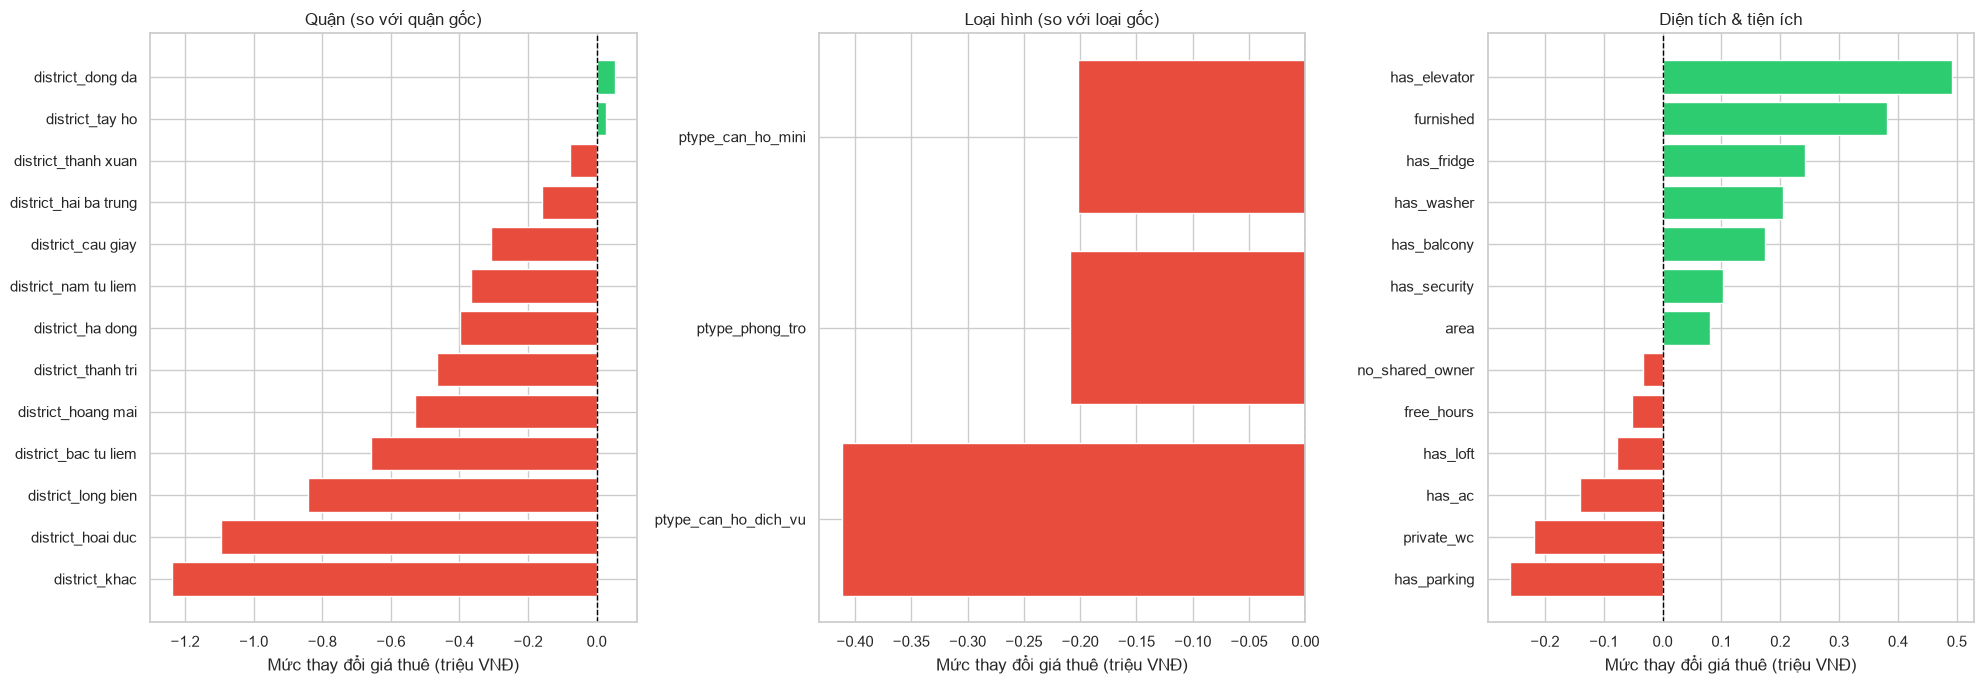

In [7]:
groups = {
    "Quận (so với quận gốc)": district_w,
    "Loại hình (so với loại gốc)": ptype_w,
    "Diện tích & tiện ích": other_w,
}
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, (title, g) in zip(axes, groups.items()):
    colors = ["#2ecc71" if v >= 0 else "#e74c3c" for v in g["Weight_Million_VND"]]
    ax.barh(g["Feature"], g["Weight_Million_VND"], color=colors)
    ax.invert_yaxis()                      # hệ số lớn nhất nằm trên cùng
    ax.axvline(0, color="black", ls="--", lw=1)
    ax.set_title(title)
    ax.set_xlabel("Mức thay đổi giá thuê (triệu VNĐ)")
plt.tight_layout()
plt.show()

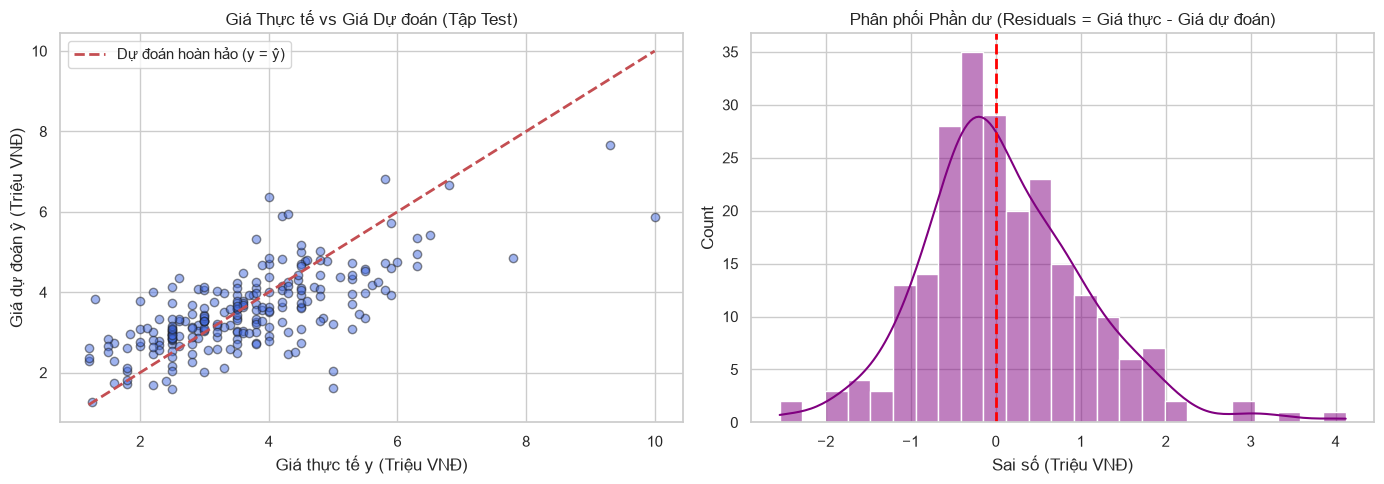

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Scatter plot: Giá thực tế vs Giá dự đoán
axes[0].scatter(y_test, y_test_predict, alpha=0.5, color="royalblue", edgecolors="k")
min_val = min(y_test.min(), y_test_predict.min())
max_val = max(y_test.max(), y_test_predict.max())
axes[0].plot([min_val, max_val], [min_val, max_val], "r--", lw=2, label="Dự đoán hoàn hảo (y = ŷ)")
axes[0].set_title("Giá Thực tế vs Giá Dự đoán (Tập Test)")
axes[0].set_xlabel("Giá thực tế y (Triệu VNĐ)")
axes[0].set_ylabel("Giá dự đoán ŷ (Triệu VNĐ)")
axes[0].legend()

# 2. Phân bố sai số (Residuals = y_test - y_test_predict)
residuals = y_test - y_test_predict
sns.histplot(residuals, bins=25, kde=True, ax=axes[1], color="purple")
axes[1].axvline(0, color="red", linestyle="--", lw=2)
axes[1].set_title("Phân phối Phần dư (Residuals = Giá thực - Giá dự đoán)")
axes[1].set_xlabel("Sai số (Triệu VNĐ)")

plt.tight_layout()
plt.show()

In [9]:
def dinh_gia_phong(
    area, district, ptype="phong_tro", asking_price=None,
    has_ac=1, furnished=1, has_balcony=0, has_elevator=0,
    has_loft=0, private_wc=1, free_hours=1, no_shared_owner=1,
    has_washer=0, has_fridge=0, has_security=1, has_parking=1
):
    # Tạo 1 dòng DataFrame toàn số 0 với đúng thứ tự cột của X_train
    row = pd.DataFrame(0.0, index=[0], columns=X.columns)
    
    # Gán diện tích và các tiện ích nhị phân
    row["area"] = area
    amenities = {
        "has_ac": has_ac, "furnished": furnished, "has_balcony": has_balcony,
        "has_elevator": has_elevator, "has_loft": has_loft, "private_wc": private_wc,
        "free_hours": free_hours, "no_shared_owner": no_shared_owner,
        "has_washer": has_washer, "has_fridge": has_fridge,
        "has_security": has_security, "has_parking": has_parking
    }
    for k, v in amenities.items():
        if k in row.columns:
            row[k] = v

    # Bật cờ One-Hot cho Quận và Loại phòng (nếu thuộc nhóm không bị drop_first)
    dist_col = f"district_{district.strip().lower()}"
    ptype_col = f"ptype_{ptype.strip().lower()}"
    if dist_col in row.columns:
        row[dist_col] = 1
    if ptype_col in row.columns:
        row[ptype_col] = 1

    # Dự đoán giá hợp lý
    pred_price = model.predict(row)[0]
    print(f"Thông tin phòng : {area}m² | Quận: {district.title()} | Loại: {ptype}")
    print(f"=> GIÁ DỰ ĐOÁN HỢP LÝ: {pred_price:.2f} triệu VNĐ/tháng")

    if asking_price is not None:
        diff = asking_price - pred_price
        print(f"=> Giá chủ trọ đăng  : {asking_price:.2f} triệu VNĐ/tháng")
        if diff < -0.3:
            print(f"=> ĐÁNH GIÁ: GIÁ HỜI! Rẻ hơn mặt bằng chung khoảng {abs(diff)*1000:.0f}k/tháng.")
        elif diff > 0.3:
            print(f"=> ĐÁNH GIÁ: HƠI ĐẮT! Cao hơn mặt bằng chung khoảng {diff*1000:.0f}k/tháng.")
        else:
            print("=> ĐÁNH GIÁ: HỢP LÝ, sát với giá thị trường.")

# --- CHẠY THỬ NGHIỆM ---
# Ví dụ: Phòng 25m2 ở Cầu Giấy, dạng chung cư mini, có điều hòa, full đồ, có thang máy, chủ đòi 4.2 triệu
dinh_gia_phong(
    area=25,
    district="cau giay",
    ptype="can_ho_mini",
    asking_price=4.2,
    has_ac=1,
    furnished=1,
    has_elevator=1,
    has_balcony=1
)

Thông tin phòng : 25m² | Quận: Cau Giay | Loại: can_ho_mini
=> GIÁ DỰ ĐOÁN HỢP LÝ: 3.81 triệu VNĐ/tháng
=> Giá chủ trọ đăng  : 4.20 triệu VNĐ/tháng
=> ĐÁNH GIÁ: HƠI ĐẮT! Cao hơn mặt bằng chung khoảng 395k/tháng.


+ chỉnh thêm tham số
+ thêm thuật toán so sánh
+ ví sao one hot ko encoding khác
+ k found validation ?